<a href="https://colab.research.google.com/github/ankxie/PHYS633/blob/main/Book/L21and22-NuclearEnergy/22-NuclearEnergy-template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## <font color="purple">Notebook 22-NuclearEnergy </font> (template)

The goal of this notebook is to explore the energy generation in the Sun and in stars more massive than the Sun.

We will start by comparing the temperature dependance of the pp chain and the CNO cycle. Then, we will look at the variation of $\epsilon$ as a function of radial coordinates inside the stars, from MESA models (the same models that we used for the previous notebook on convection.)

In [1]:
import numpy as np, copy
import matplotlib.pyplot as plt
%matplotlib inline
from astropy import constants as const
import astropy.units as u
from astropy.units import cds
cds.enable()

from scipy.optimize import curve_fit

## 1. At home: pp vs CNO rates

> **TODO**
> 1. Make a plot of $\log(\epsilon)$ as a function of $\log(T)$ for the PP-I chain and the CNO cycle, based on the expression given in class (from Kip 18.5.1). Use the temperature range already given in the code below.
>
> 2. In both cases (PP-I and CNO), by how much does the $\epsilon$ changes for a change of temperature of one order of magnitude?
>
>3. If you were to reproduce $\epsilon$ in the range of temperature below by a power law of the form $\epsilon \propto T^\nu$, what would the index $\nu$ of the power law be? (Graph a curve to find your answer.)

PP-1: 7.673568883993037
CNO: 39.02284441747653


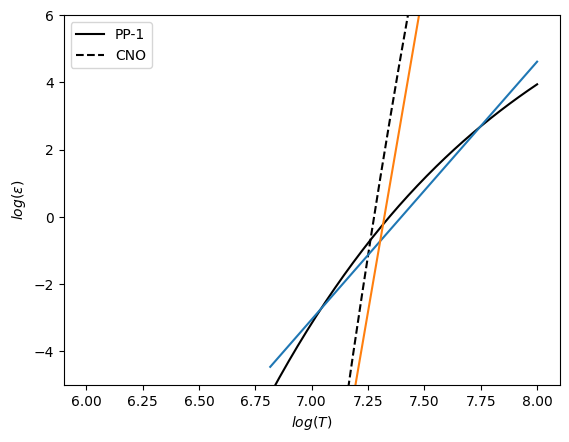

In [64]:
fig, ax = plt.subplots(1,1)
ax.set_ylim(-5,6)

logT = np.linspace(6,8,50)


#########################
# At home

T6 = (10** (logT - 6))
rho = 1
x_h = 0.7
xcno = 0.01

gpp = 1 + 0.0123 * T6 **(1/3) +0.0109 * T6 **(2/3) + 0.0009 * T6
pp1 = 2.38 * (10**6) * gpp * (rho) * (x_h**2) * (T6**(-2/3)) * np.exp(-33.8 * (T6 ** (-1/3)))
gcno = 1 + 0.0027 * T6 **(1/3) - 0.00778 * T6 **(2/3) - 0.000149 * T6
cno = 8.67 * (10**27) * gcno * (rho) * x_h * xcno * (T6 ** (-2/3)) * np.exp(-152.83 * (T6 ** (-1/3)))

def func(x, a, b):
    return a * x + b

popt_pp1, pcov_pp1 = curve_fit(func, logT[20:50], np.log(pp1[20:50]))
popt_cno, pcov_cno = curve_fit(func, logT[20:50], np.log(cno[20:50]))


ax.plot(logT, np.log(pp1), c = 'k', label = 'PP-1')
ax.plot(logT, np.log(cno), ls = '--', c = 'k', label = 'CNO')
ax.plot(logT[20:50], func(logT[20:50], *popt_pp1))
ax.plot(logT[20:50], func(logT[20:50], *popt_cno))

ax.set_ylabel(r'$log(\epsilon)$')
ax.set_xlabel(r'$log(T)$')
ax.legend()

print('PP-1:', popt_pp1[0])
print('CNO:', popt_cno[0])


> **TODO**: Write a caption for your graph, and answer the questions asked.

Caption: $log(\epsilon)$ vs $log(T)$ of the PP-1 chain and CNO cycle for a star with a density of $\rho = 1\space g/cm^3$, and Sun-like composition ($X_H = .7$, $X_{CNO} = .01$). The Sun's core has a temperature of around $log(T) = 7$. At these temperatures, the PP-1 chain is more efficient at releasing energy.

Answer to Questions: For the PP-1 chain, $\epsilon$ increases by 6 orders of magnitude when $T$ increases by 1 order of magntiude. For the CNO cycle, $\epsilon$ increases by ~38 orders of magnitude when $T$ increases by 1 order of magntiude. The index $\nu$ would be ~8 for the PP-1 chain, and ~39 for the CNO cycle.

## 2. Let's look at the energy generation in our MESA models



### Reading in the models

First, use the cell below to read in the two MESA models from the convection notebook for the Sun (in variable `Msun`) and for a 10 $M_\odot$ star (in variable `M10`).

In [3]:
def read_model(file):

    return np.genfromtxt(file, skip_header=5, names=True)

Msun = read_model('https://raw.githubusercontent.com/veropetit/PHYS633-F2024/main/Book/L19-Convection/19-Sun-profile8.data')
M10  = read_model('https://raw.githubusercontent.com/veropetit/PHYS633-F2024/main/Book/L19-Convection/19-M10-profile8.data')

### 1. In class: we will look at the energy generation in the Solar model.

In MESA, the column named `eps_nuc` gives the total power per gram coming from all of the nuclear reactions. The columns `pp` and `cno` give the power/g coming from the PP (I, II, and III) chains and the CNO cycle, respectively.

We will make a gapph of $\epsilon_\mathrm{nuc}$, $\epsilon_\mathrm{pp}$ and $\epsilon_\mathrm{cno}$ as a function of radius, and then compare the values in MESA with the values we get from the formula given in the textbook.

### At home:

> **TODO**
> 1. On the left graph, add curves for the $\epsilon_\mathrm{nuc}$, $\epsilon_\mathrm{pp}$ and $\epsilon_\mathrm{cno}$ given by the MESA model.
>
> 2. Make a similar plot for the 10 $M_\odot$ model on the right graph.
>
> 3. In the interpretation box below, comment on the similarities/differences between the two models.
>
> 4. Use the analytical expression for $\epsilon_\mathrm{pp-1}$ and $\epsilon_\mathrm{cno}$ from Part 1 to calculate your expected values for $\epsilon_\mathrm{pp-1}$ and $\epsilon_\mathrm{cno}$ in both models, and add these curves to your plots. In the MESA model, you will some useful columns such as:
>    * `logRho` for the logarithm10 of the density in g/cm2
>    * `logT` for the logarithm10 of the temperature in K
>    * `h1` for the mass fraction of hydrogen
>    * `c12`, `n14`, `o16`,`o18` for the mass fraction of important isotopes of carbon, nitrogen, and oxygen.
>
> 5. In the interpretation box below, compare your calculation in #4 to the real $\epsilon$ in the models. If there are any differences, comment on what could explain these discrepencies.

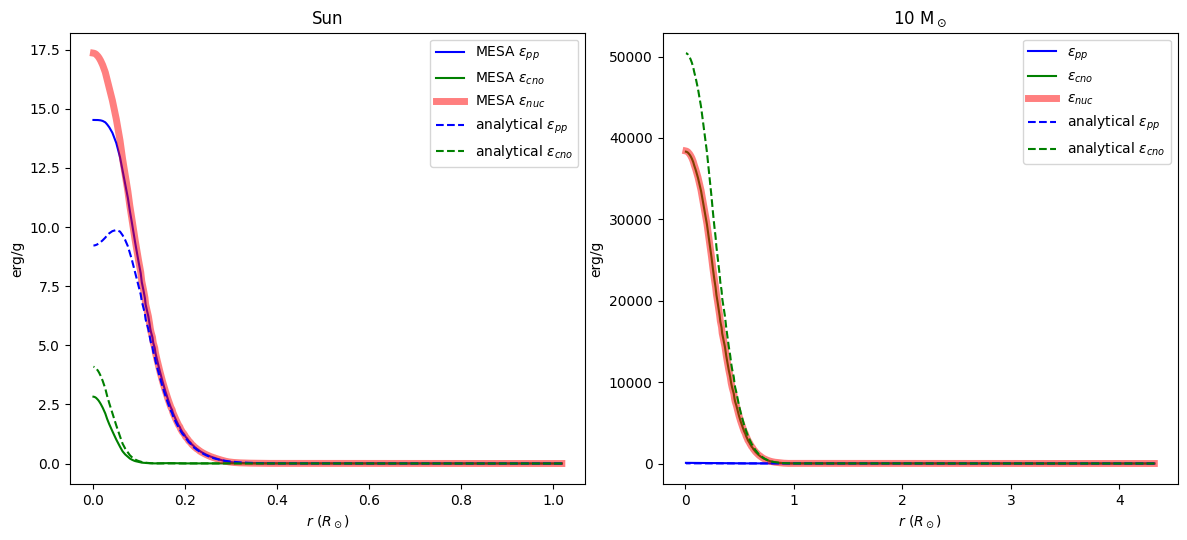

In [4]:
from astropy.units.si import Ms
fig, ax = plt.subplots(1,2, figsize=(12,5.5))

ax[0].set_title('Sun')
ax[1].set_title(r'10 M$_\odot$')

ax[0].set_xlabel(r'$r$ ($R_\odot$)')
ax[1].set_xlabel(r'$r$ ($R_\odot$)')

ax[0].set_ylabel('erg/g')
ax[1].set_ylabel('erg/g')

plt.tight_layout()


#########################
# In class

ax[0].plot(Msun['radius'], Msun['pp'], c = 'b', label = r'MESA $\epsilon_{pp}$')
ax[0].plot(Msun['radius'], Msun['cno'], c = 'g', label = r'MESA $\epsilon_{cno}$')
ax[0].plot(Msun['radius'], Msun['eps_nuc'],c = 'r', label = r'MESA $\epsilon_{nuc}$', lw = 5, alpha = 0.5)


#########################
# At home

ax[1].plot(M10['radius'], M10['pp'], c = 'b', label = r'$\epsilon_{pp}$')
ax[1].plot(M10['radius'], M10['cno'], c = 'g', label = r'$\epsilon_{cno}$')
ax[1].plot(M10['radius'], M10['eps_nuc'],c = 'r', label = r'$\epsilon_{nuc}$', lw = 5, alpha = 0.5)

#Sun
Msun_T6 = (10 ** Msun['logT']) / 10**6
Msun_T9 = (10 ** Msun['logT']) / 10**9
#gpp = 1 + 0.0123 * Msun_T6 **(1/3) +0.0109 * Msun_T6 **(2/3) + 0.0009 * Msun_T6
#pp1 = 2.38 * (10**6) * gpp * (10 ** Msun['logRho']) * (Msun['h1']**2) * (Msun_T6**(-2/3)) * np.exp(-33.8 * (Msun_T6 ** (-1/3)))

gpp = 1 + 3.82 * Msun_T9 + 1.51 * (Msun_T9** 2) + 0.144 * (Msun_T9** 3) - 0.0114 * (Msun_T9** 4)
pp1 = 2.57 * (10**4) * gpp * (10 ** Msun['logRho']) * (Msun['h1']**2) * (Msun_T9**(-2/3)) * np.exp(-3.38 * (Msun_T9 ** (-1/3)))


gcno = 1 + 0.0027 * Msun_T6 **(1/3) - 0.00778 * Msun_T6 **(2/3) - 0.000149 * Msun_T6
xcno = Msun['c12'] + Msun['n14'] + Msun['o16'] + Msun['o18']
cno = 8.67 * (10**27) * gcno * (10 ** Msun['logRho']) * Msun['h1'] * xcno * (Msun_T6 ** (-2/3)) * np.exp(-152.83 * (Msun_T6 ** (-1/3)))

ax[0].plot(Msun['radius'], pp1, c = 'b', label = r'analytical $\epsilon_{pp}$', ls = '--')
ax[0].plot(Msun['radius'], cno, c = 'g', label = r'analytical $\epsilon_{cno}$', ls = '--')

#M10
M10_T6 = (10 ** M10['logT']) / 10**6
gpp = 1 + 0.0123 * M10_T6 **(1/3) +0.0109 * M10_T6 **(2/3) + 0.0009 * M10_T6
pp1 = 2.38 * (10**6) * gpp * (10 ** M10['logRho']) * (M10['h1']**2) * (M10_T6**(-2/3)) * np.exp(-33.8 * (M10_T6 ** (-1/3)))

gcno = 1 + 0.0027 * M10_T6 **(1/3) - 0.00778 * M10_T6 **(2/3) - 0.000149 * M10_T6
xcno = M10['c12'] + M10['n14'] + M10['o16'] + M10['o18']
cno = 8.67 * (10**27) * gcno * (10 ** M10['logRho']) * M10['h1'] * xcno * (M10_T6 ** (-2/3)) * np.exp(-152.83 * (M10_T6 ** (-1/3)))

ax[1].plot(M10['radius'], pp1, c = 'b', label = r'analytical $\epsilon_{pp}$', ls = '--')
ax[1].plot(M10['radius'], cno, c = 'g', label = r'analytical $\epsilon_{cno}$', ls = '--')


ax[0].legend()
ax[1].legend()



> **TODO** Write a caption for your graph, and answer the questions asked.

Caption: The power per gram produced from the PP-1 chain, the CNO cycle, and all nuclear reactions vs radius for the Sun (left plot) and a 10 solar mass star (right plot).

Answer to Questions:
The Sun's energy production is dominated by the PP chain, and the CNO cycle contributes little to the overall energy production. For a 10 solar mass star, the CNO cycle is responsible for almost all of the energy production, and the PP chain contributes very little. Nuclear reactions for both stars only happen in the core, and power per mass drops sharply as radius increases. Our analytical solution for the $\epsilon$ reproduces the same shape as the curves for $\epsilon$ from the MESA models. However, the analytical solution overestimates $\epsilon_\mathrm{cno}$ while underestimating $\epsilon_\mathrm{pp}$. Perhaps this discrepency could be explained by the sheilding factor, which I do not consider in my calculations.